# Single-location state and measurement optimization

$M=1$, $K\in\{3,4,5\}$, $N\in\{2,4,6,8,10\}$, with 50 instances per dimension, field family and $K$. The same field instances are used at every sensor budget. Field priors are uniform.

Dicke-sector weights and the POVM are optimized jointly by an exact SDP, subject to numerical feasibility and optimality checks. Reflection symmetry is not imposed. Product, GHZ and equal-sector states are unchanged; PGM uses the same weights as the optimal-POVM comparison.


## Environment

Install missing dependencies in the active kernel. Restart the kernel after installation if already loaded packages were upgraded.

In [9]:
from pathlib import Path
import sys
import importlib.util
import subprocess

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT / "problem-3-single-location"
if not (ROOT / "src").is_dir():
    raise FileNotFoundError("Open from the project folder or repository root")

required = ("cvxpy", "numpy", "pandas", "scipy", "matplotlib")
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    print("Installing missing dependencies into the active kernel:", ", ".join(missing))
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-r", str(ROOT / "requirements.txt")
    ])
    importlib.invalidate_caches()
    raise RuntimeError("Dependencies installed. Restart the kernel, then run all cells.")
print("Python environment:", sys.executable)


Python environment: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/.venv/bin/python


In [10]:
from IPython.display import display
import pandas as pd

sys.path.insert(0, str(ROOT))
KS = (3, 4, 5)
NS = (2, 4, 6, 8, 10)
RUN_ANALYSIS = False
SOLVER = "auto"
SDP_EPS = 1e-8


## Saved results

The runner validates the generated inputs in `inputs/1d/` and `inputs/2d/`. Results and resumable checkpoints are saved under `results/exact_sdp/`. With `RUN_ANALYSIS=False`, only saved results are loaded.


In [11]:
if RUN_ANALYSIS:
    from src.analysis import run_analysis
    status = display({"text/plain": "Starting analysis"}, raw=True, display_id=True)

    def show_progress(message):
        status.update({"text/plain": message}, raw=True)

    measurements = run_analysis(ROOT, ks=KS, ns=NS, progress=show_progress, solver=SOLVER, sdp_eps=SDP_EPS)
else:
    measurements = pd.read_csv(ROOT / "results/exact_sdp/measurements.csv")
    print(f"Loaded {len(measurements)} saved state evaluations; M=1, K={KS}, N={NS}.")


Loaded 18000 saved state evaluations; M=1, K=(3, 4, 5), N=(2, 4, 6, 8, 10).


## Results

Each figure retains three panels: Gaussian, sinusoidal and quadratic. Performance curves give 1D and 2D equal weight and average equally over $K=3,4,5$, using 300 instances per curve point. Figure 1 compares four states with optimal POVMs. Figure 2 shows paired excess error from PGM as grouped bars. Curves and bars show means; summary tables include stratified 95% confidence intervals. Separate tables retain each dimension and $K$.

Figure 3 pools the optimized weights from both dimensions and compares $p_w$ with $p_{N-w}$, using the existing sensor-budget colors. Central sectors are omitted. Reflection asymmetry is a diagnostic, not an optimization constraint.


Optimal-POVM error across K


state                          equal                  ghz  \
family     m n                                              
gaussian   1 2   0.603006 ± 0.006069  0.581913 ± 0.006517   
             4   0.526545 ± 0.008692  0.523380 ± 0.006264   
             6   0.466154 ± 0.010563  0.517076 ± 0.005824   
             8   0.417378 ± 0.011920  0.512184 ± 0.006064   
             10  0.377781 ± 0.012822  0.506269 ± 0.005300   
quadratic  1 2   0.609056 ± 0.005130  0.586190 ± 0.005618   
             4   0.531410 ± 0.007564  0.510683 ± 0.005403   
             6   0.467087 ± 0.009357  0.494853 ± 0.004030   
             8   0.412597 ± 0.010687  0.497080 ± 0.004221   
             10  0.366692 ± 0.011584  0.500154 ± 0.004741   
sinusoidal 1 2   0.487629 ± 0.009035  0.507585 ± 0.005838   
             4   0.366925 ± 0.012177  0.501672 ± 0.005024   
             6   0.286181 ± 0.013328  0.500417 ± 0.005486   
             8   0.230526 ± 0.013558  0.497306 ± 0.004350   
             10  0.191507 ± 0.013343  0.500029 ± 0.005448   

state                      optimized              product  
family     m n                                             
gaussian   1 2   0.581757 ± 0.006537  0.618601 ± 0.005505  
             4   0.493146 ± 0.008457  0.575598 ± 0.007209  
             6   0.428267 ± 0.010320  0.545303 ± 0.008325  
             8   0.379660 ± 0.011408  0.521574 ± 0.009150  
             10  0.340183 ± 0.012281  0.502015 ± 0.009794  
quadratic  1 2   0.586130 ± 0.005629  0.624609 ± 0.004628  
             4   0.493182 ± 0.007236  0.582144 ± 0.006165  
             6   0.425342 ± 0.008947  0.551460 ± 0.007215  
             8   0.369454 ± 0.010274  0.526867 ± 0.008011  
             10  0.324223 ± 0.011083  0.506177 ± 0.008642  
sinusoidal 1 2   0.475574 ± 0.008252  0.506728 ± 0.008907  
             4   0.345549 ± 0.011440  0.431738 ± 0.011068  
             6   0.262434 ± 0.012553  0.384689 ± 0.012092  
             8   0.206171 ± 0.012784  0.350931 ± 0.012666  
             10  0.167572 ± 0.012622  0.325009 ± 0.013011

PGM excess error across K


state                          equal                  ghz  \
family     m n                                              
gaussian   1 2   0.012279 ± 0.000504  0.018242 ± 0.000834   
             4   0.009698 ± 0.000532  0.013968 ± 0.001079   
             6   0.008102 ± 0.000543  0.014976 ± 0.001191   
             8   0.006949 ± 0.000553  0.014973 ± 0.001168   
             10  0.005966 ± 0.000542  0.015129 ± 0.001183   
quadratic  1 2   0.014458 ± 0.000486  0.021307 ± 0.000816   
             4   0.011824 ± 0.000499  0.016541 ± 0.001101   
             6   0.008782 ± 0.000515  0.011998 ± 0.001129   
             8   0.006890 ± 0.000494  0.013064 ± 0.001148   
             10  0.005709 ± 0.000476  0.013675 ± 0.001157   
sinusoidal 1 2   0.010730 ± 0.000583  0.013317 ± 0.001145   
             4   0.005811 ± 0.000508  0.013080 ± 0.001119   
             6   0.003618 ± 0.000436  0.012083 ± 0.001068   
             8   0.002319 ± 0.000363  0.012077 ± 0.001083   
             10  0.001516 ± 0.000297  0.011791 ± 0.001094   

state                      optimized              product  
family     m n                                             
gaussian   1 2   0.017672 ± 0.000824  0.011067 ± 0.000441  
             4   0.012739 ± 0.000927  0.009613 ± 0.000421  
             6   0.010590 ± 0.000931  0.008640 ± 0.000434  
             8   0.008906 ± 0.000948  0.007938 ± 0.000443  
             10  0.007499 ± 0.000884  0.007404 ± 0.000448  
quadratic  1 2   0.021177 ± 0.000804  0.012787 ± 0.000430  
             4   0.015204 ± 0.000971  0.011607 ± 0.000387  
             6   0.010355 ± 0.000903  0.010403 ± 0.000401  
             8   0.008394 ± 0.000801  0.009378 ± 0.000415  
             10  0.006805 ± 0.000724  0.008536 ± 0.000422  
sinusoidal 1 2   0.012819 ± 0.000983  0.010713 ± 0.000496  
             4   0.007391 ± 0.000826  0.006371 ± 0.000460  
             6   0.004360 ± 0.000641  0.004851 ± 0.000425  
             8   0.002425 ± 0.000481  0.003965 ± 0.000396  
             10  0.001478 ± 0.000350  0.003365 ± 0.000372

Optimal-POVM error by K


state                                      equal                  ghz  \
dimension family     k m n                                              
1         gaussian   3 1 2   0.467947 ± 0.019844  0.438086 ± 0.020694   
                         4   0.363450 ± 0.027010  0.368898 ± 0.015309   
                         6   0.289012 ± 0.031737  0.380987 ± 0.016169   
                         8   0.236023 ± 0.034734  0.379267 ± 0.020460   
                         10  0.199470 ± 0.035557  0.385625 ± 0.019695   
...                                          ...                  ...   
2         sinusoidal 5 1 2   0.563900 ± 0.011950  0.602733 ± 0.002070   
                         4   0.435920 ± 0.019011  0.604076 ± 0.003438   
                         6   0.344942 ± 0.022613  0.606892 ± 0.005160   
                         8   0.280831 ± 0.025123  0.605827 ± 0.004893   
                         10  0.235857 ± 0.026345  0.604562 ± 0.003883   

state                                  optimized              product  
dimension family     k m n                                             
1         gaussian   3 1 2   0.437963 ± 0.020739  0.490429 ± 0.018158  
                         4   0.321544 ± 0.024624  0.430324 ± 0.023211  
                         6   0.244913 ± 0.031073  0.389813 ± 0.026266  
                         8   0.197984 ± 0.032946  0.359405 ± 0.028363  
                         10  0.164555 ± 0.033431  0.335332 ± 0.029887  
...                                          ...                  ...  
2         sinusoidal 5 1 2   0.559118 ± 0.010563  0.579441 ± 0.012245  
                         4   0.424364 ± 0.017550  0.499414 ± 0.017113  
                         6   0.329328 ± 0.021286  0.447768 ± 0.019497  
                         8   0.264944 ± 0.024112  0.410121 ± 0.020972  
                         10  0.220086 ± 0.025953  0.381020 ± 0.021994  

[90 rows x 4 columns]

PGM excess error


state                                      equal                  ghz  \
dimension family     k m n                                              
1         gaussian   3 1 2   0.010108 ± 0.001094  0.017707 ± 0.002356   
                         4   0.005258 ± 0.001291  0.013372 ± 0.002834   
                         6   0.002909 ± 0.001192  0.013300 ± 0.002881   
                         8   0.001800 ± 0.001062  0.012906 ± 0.002973   
                         10  0.001234 ± 0.000910  0.014713 ± 0.002733   
...                                          ...                  ...   
2         sinusoidal 5 1 2   0.013140 ± 0.001401  0.010501 ± 0.002717   
                         4   0.007415 ± 0.000931  0.010535 ± 0.002835   
                         6   0.005020 ± 0.001053  0.011578 ± 0.002706   
                         8   0.003214 ± 0.000911  0.010533 ± 0.002735   
                         10  0.002136 ± 0.000746  0.010991 ± 0.002501   

state                                  optimized              product  
dimension family     k m n                                             
1         gaussian   3 1 2   0.016920 ± 0.002414  0.009060 ± 0.000880  
                         4   0.006901 ± 0.002435  0.006372 ± 0.000912  
                         6   0.003163 ± 0.002077  0.004859 ± 0.000981  
                         8   0.002376 ± 0.001984  0.003906 ± 0.000991  
                         10  0.001396 ± 0.001370  0.003254 ± 0.000976  
...                                          ...                  ...  
2         sinusoidal 5 1 2   0.013388 ± 0.001936  0.013577 ± 0.001279  
                         4   0.008707 ± 0.001253  0.007799 ± 0.001003  
                         6   0.005967 ± 0.001436  0.005965 ± 0.000883  
                         8   0.003194 ± 0.000939  0.004933 ± 0.000831  
                         10  0.002074 ± 0.000806  0.004236 ± 0.000803  

[90 rows x 4 columns]

Reflection asymmetry


,dimension,family,k,m,n,count,mean,ci95,lower95,upper95,maximum_asymmetry,fraction_within_tolerance,tolerance
0,1,gaussian,3,1,2,50,2.769160e-10,4.286881e-10,-1.517721e-10,7.056040e-10,1.034925e-08,1.0,0.00001
1,1,gaussian,3,1,4,50,4.907462e-13,8.133169e-13,-3.225707e-13,1.304063e-12,2.024869e-11,1.0,0.00001
2,1,gaussian,3,1,6,50,4.941977e-11,7.418761e-11,-2.476785e-11,1.236074e-10,1.692255e-09,1.0,0.00001
3,1,gaussian,3,1,8,50,4.935452e-09,9.917747e-09,-4.982295e-09,1.485320e-08,2.467625e-07,1.0,0.00001
4,1,gaussian,3,1,10,50,2.298236e-13,1.345499e-13,9.527373e-14,3.643735e-13,3.002803e-12,1.0,0.00001
...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,2,sinusoidal,5,1,2,50,7.728751e-13,9.438525e-13,-1.709774e-13,1.716728e-12,2.095618e-11,1.0,0.00001
86,2,sinusoidal,5,1,4,50,5.541840e-11,1.095043e-10,-5.408595e-11,1.649227e-10,2.725280e-09,1.0,0.00001
87,2,sinusoidal,5,1,6,50,1.278615e-10,2.542438e-10,-1.263823e-10,3.821054e-10,6.327086e-09,1.0,0.00001
88,2,sinusoidal,5,1,8,50,1.270663e-10,1.788204e-10,-5.175416e-11,3.058867e-10,4.005023e-09,1.0,0.00001


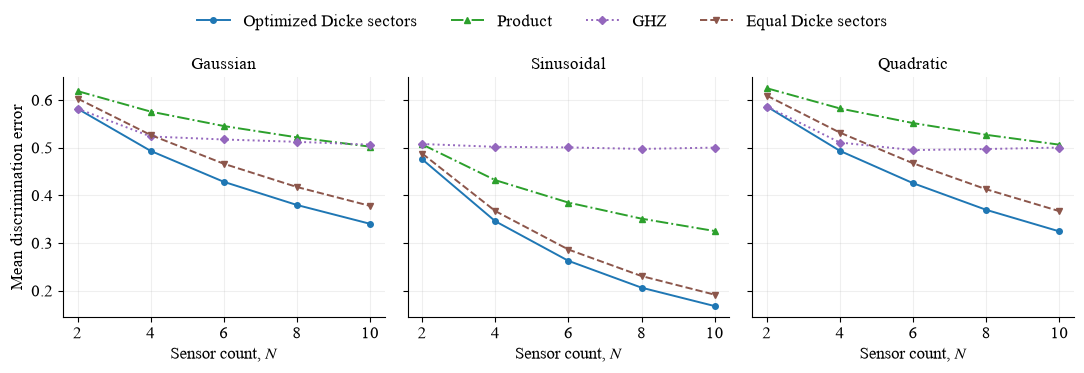

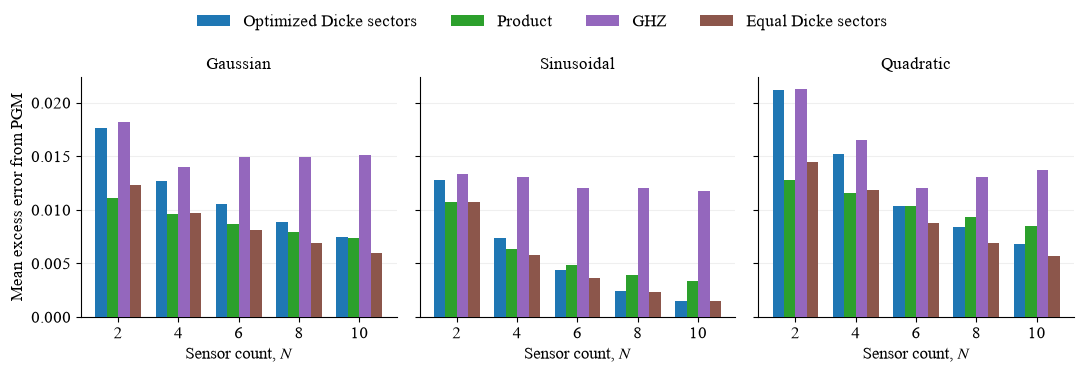

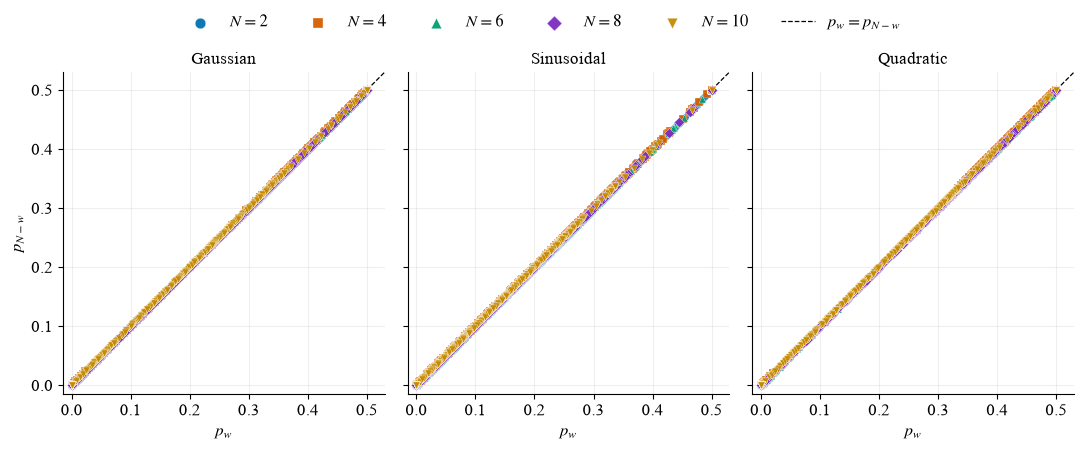

In [12]:
import importlib
import matplotlib.pyplot as plt
import src.reporting as reporting

reporting = importlib.reload(reporting)
results = reporting.make_results(measurements, ROOT)
for name in ("overall_errors", "overall_degradation", "errors", "degradation", "symmetry"):
    print({"overall_errors": "Optimal-POVM error across K", "overall_degradation": "PGM excess error across K", "errors": "Optimal-POVM error by K", "degradation": "PGM excess error",
           "symmetry": "Reflection asymmetry"}[name])
    table = results[name]
    if name != "symmetry":
        table = table.assign(estimate=table.apply(
            lambda r: f"{r['mean']:.6f} ± {r['ci95']:.6f}", axis=1))
        index = [col for col in ("dimension", "family", "k", "m", "n") if col in table.columns]
        table = table.pivot(index=index, columns="state", values="estimate")
    display(table)
for figure in results["figures"]:
    display(figure)
    plt.close(figure)


Figures are exported as PDF and PNG under `results/exact_sdp/`, together with error summaries, sector weights, runtime and numerical validation tables.
